# Assignment 3 - step 3: Text Classification with a Transformer

In this step I train a transformer-based model for multi-label text classification on the prepared Gutenberg chunk dataset from Step 1.

### Interpretation of the Transformer requirement

This step implements Transformer-based text classification using a pretrained BERT model
with a task-specific classification head.

Strictly speaking, BERT is an encoder-based Transformer rather than a generative
encoder-decoder architecture. In this notebook, the Transformer encoder is combined with
a downstream classification layer to perform multi-label classification on text chunks.

### Why BERT-base-uncased was chosen

BERT-base-uncased was selected because it is a strong and well-established pretrained
language model with broad documentation and stable TensorFlow support.

Larger Transformer models may offer better performance, but they also require
substantially more memory and training time. 

For this assignment, BERT-base provides a
good trade-off between classification quality, training feasibility, and reproducibility
on limited hardware.

## Hyperparameter choices

The main hyperparameters were chosen to balance performance and feasibility.

- `max_length = 256`: the texts were already split into chunks in Step 1, so using much longer sequences would increase cost without adding much extra context.
- `batch_size = 8`: this keeps memory usage manageable for transformer fine-tuning.
- `learning_rate = 2e-5`: this is a common fine-tuning learning rate for BERT and keeps updates small enough not to destroy pretrained representations too quickly.
- `epochs = 5` together with early stopping: the model is allowed to continue if validation improves, but the training can stop early when the model begins to overfit.

In [3]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import f1_score, hamming_loss, precision_score, recall_score

from transformers import AutoTokenizer, TFAutoModelForSequenceClassification

SEED = 42
tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)

PROJECT_DIR = Path.cwd()
PREP_DIR = PROJECT_DIR / "data" / "processed"
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

CHUNKS_PATH = PREP_DIR / "chunks_prepared.parquet"

MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 256

MAX_TRAIN_SAMPLES = 12000
MAX_VAL_SAMPLES = 2000
MAX_TEST_SAMPLES = 2000

BATCH_SIZE = 8
EPOCHS = 5
LEARNING_RATE = 2e-5

# Load data

In [6]:
chunks_df = pd.read_parquet(CHUNKS_PATH)
chunks_df["labels"] = chunks_df["labels"].apply(json.loads)

print(chunks_df.columns.tolist())
chunks_df.head(2)

['book_id', 'chunk_id', 'text_id', 'title', 'authors', 'split', 'labels', 'text_chunk', 'chunk_words']


,book_id,chunk_id,text_id,title,authors,split,labels,text_chunk,chunk_words
0,25698,25698_0,25698,"Think Before You Speak; Or, The Three Wishes","Dorset, Catherine Ann Turner, 1750?-1817?; Lep...",test,[Category: Children & Young Adult Reading],(This file was produced from images generously...,256
1,25698,25698_1,25698,"Think Before You Speak; Or, The Three Wishes","Dorset, Catherine Ann Turner, 1750?-1817?; Lep...",test,[Category: Children & Young Adult Reading],"own good man To his clean hearth, his pipe, an...",256


## Reduce the dataset size for this step

I reuse the same prepared chunk dataset from Step 1, but I train the transformer on a reduced subset.

The reason is computational cost. A transformer is much heavier than the Conv1D and LSTM models from Step 2, both in memory usage and in training time.

# Split and reduce dataset

In [7]:
train_df = chunks_df[chunks_df["split"] == "train"].copy()
val_df = chunks_df[chunks_df["split"] == "val"].copy()
test_df = chunks_df[chunks_df["split"] == "test"].copy()

if len(train_df) > MAX_TRAIN_SAMPLES:
    train_df = train_df.sample(MAX_TRAIN_SAMPLES, random_state=SEED)

if len(val_df) > MAX_VAL_SAMPLES:
    val_df = val_df.sample(MAX_VAL_SAMPLES, random_state=SEED)

if len(test_df) > MAX_TEST_SAMPLES:
    test_df = test_df.sample(MAX_TEST_SAMPLES, random_state=SEED)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (12000, 9)
Validation: (2000, 9)
Test: (2000, 9)


## Why I reduce the dataset for this step

Transformer fine-tuning is much more computationally expensive than the Conv1D and LSTM models from Step 2.  
For that reason I keep the same prepared dataset structure, but use a smaller subset of chunks for training and evaluation.

# Prepare labels

In [8]:
mlb = MultiLabelBinarizer()

y_train = mlb.fit_transform(train_df["labels"])
y_val = mlb.transform(val_df["labels"])
y_test = mlb.transform(test_df["labels"])

label_names = mlb.classes_.tolist()
num_labels = len(label_names)

print("Number of labels:", num_labels)
print(label_names)

Number of labels: 10
['Category: Adventure', 'Category: American Literature', 'Category: Biographies', 'Category: British Literature', 'Category: Children & Young Adult Reading', 'Category: Essays, Letters & Speeches', 'Category: History - American', 'Category: History - Modern (1750+)', 'Category: Humour', 'Category: Novels']


# Prepare text arrays

In [10]:
x_train = train_df["text_chunk"].astype(str).to_numpy()
x_val = val_df["text_chunk"].astype(str).to_numpy()
x_test = test_df["text_chunk"].astype(str).to_numpy()

# Tokenization

## Pretrained tokenizer

I use the tokenizer that belongs to the pretrained BERT model.

This is important because the model was pretrained with that exact tokenization scheme. If I used a different tokenization pipeline, the token indices would no longer correspond properly to the pretrained embedding space. So this is not just a convenience choice, but a requirement for using the pretrained model correctly.

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_texts(texts, tokenizer, max_length):
    return tokenizer(
        list(texts),
        padding="max_length",
        truncation=True,
        max_length=max_length,
        return_tensors="np"
    )

train_encodings = tokenize_texts(x_train, tokenizer, MAX_LENGTH)
val_encodings = tokenize_texts(x_val, tokenizer, MAX_LENGTH)
test_encodings = tokenize_texts(x_test, tokenizer, MAX_LENGTH)

## Why I use BERT tokenization

A pretrained BERT model expects tokenized input in the format used during pretraining.  
Therefore I use the matching pretrained tokenizer instead of a custom tokenizer or a TextVectorization layer.

This is important because the embedding layer and transformer weights were trained together with this tokenization scheme.

# Build tf.data datasets

In [12]:
def make_tf_dataset(encodings, labels, batch_size, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices((
        {
            "input_ids": encodings["input_ids"],
            "attention_mask": encodings["attention_mask"]
        },
        labels.astype("float32")
    ))
    
    if shuffle:
        dataset = dataset.shuffle(buffer_size=len(labels), seed=SEED)
    
    return dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)

train_ds = make_tf_dataset(train_encodings, y_train, BATCH_SIZE, shuffle=True)
val_ds = make_tf_dataset(val_encodings, y_val, BATCH_SIZE, shuffle=False)
test_ds = make_tf_dataset(test_encodings, y_test, BATCH_SIZE, shuffle=False)

# Build model

I keep the classification setup simple on purpose.

The transformer itself already contains the main modelling power: contextual embeddings, self-attention and positional information. 
Because of that, I do not add extra custom blocks or multiple dense stages on top.

In [ ]:
transformer_model = TFAutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    problem_type="multi_label_classification"
)

In [ ]:
optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE)

transformer_model.compile(
    optimizer=optimizer,
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=[
        tf.keras.metrics.BinaryAccuracy(threshold=0.0, name="binary_accuracy"),
        tf.keras.metrics.AUC(name="auc_roc", multi_label=True),
        tf.keras.metrics.AUC(name="auc_pr", curve="PR", multi_label=True),
    ],
)

## Callbacks

I use two callbacks: `EarlyStopping` and `ModelCheckpoint`.

`EarlyStopping` monitors validation loss and stops training when the model no longer improves. This is important because a pretrained transformer can start overfitting quite quickly on a reduced dataset. I also use `restore_best_weights=True`, so the final model corresponds to the best validation result rather than the last epoch.

`ModelCheckpoint` saves the best model during training. This makes the experiment reproducible and ensures that I do not accidentally evaluate a later, worse epoch.

In [16]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "bert_transformer_best.keras"),
        monitor="val_loss",
        save_best_only=True
    )
]

In [17]:
history = transformer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/5

1500/1500 [==============================] - ETA: 0s - loss: 0.3118 - binary_accuracy: 0.8766 - auc_roc: 0.6423 - auc_pr: 0.4041

c:\Users\chupr\Desktop\projects\deep-learning-minor-assignment-3\.venv\lib\site-packages\transformers\generation\tf_utils.py:465: UserWarning: `seed_generator` is deprecated and will be removed in a future version.
  warnings.warn("`seed_generator` is deprecated and will be removed in a future version.", UserWarning)


1500/1500 [==============================] - 6890s 5s/step - loss: 0.3118 - binary_accuracy: 0.8766 - auc_roc: 0.6423 - auc_pr: 0.4041 - val_loss: 0.2794 - val_binary_accuracy: 0.8903 - val_auc_roc: 0.7047 - val_auc_pr: 0.4607
Epoch 2/5
1500/1500 [==============================] - 7257s 5s/step - loss: 0.1771 - binary_accuracy: 0.9362 - auc_roc: 0.8378 - auc_pr: 0.7188 - val_loss: 0.3108 - val_binary_accuracy: 0.8812 - val_auc_roc: 0.7328 - val_auc_pr: 0.4704
Epoch 3/5
1500/1500 [==============================] - 7428s 5s/step - loss: 0.0972 - binary_accuracy: 0.9690 - auc_roc: 0.9252 - auc_pr: 0.8677 - val_loss: 0.3622 - val_binary_accuracy: 0.8779 - val_auc_roc: 0.7199 - val_auc_pr: 0.4428


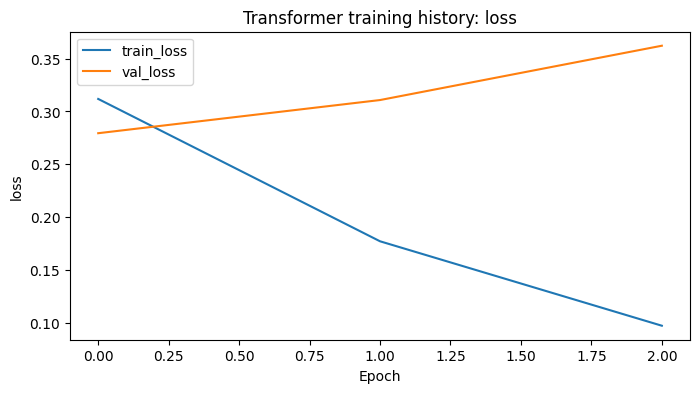

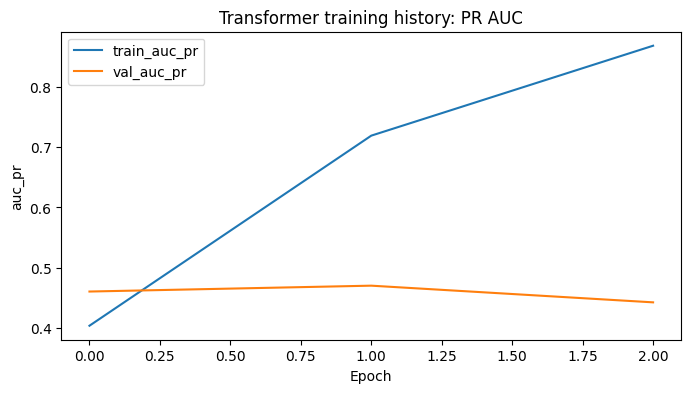

In [18]:
def plot_history(history, metric_name, title):
    plt.figure(figsize=(8, 4))
    plt.plot(history.history[metric_name], label=f"train_{metric_name}")
    plt.plot(history.history[f"val_{metric_name}"], label=f"val_{metric_name}")
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel(metric_name)
    plt.legend()
    plt.show()

plot_history(history, "loss", "Transformer training history: loss")
plot_history(history, "auc_pr", "Transformer training history: PR AUC")

## I do not rely on binary accuracy alone

This is a multi-label classification problem, so binary accuracy is not the main metric.

The reason is that many label positions are zeros. Because of that, a model can get a relatively high binary accuracy even if it is still weak at identifying the positive labels.

For this reason I focus mainly on:
- micro-F1,
- macro-F1,
- samples-F1,
- precision,
- recall,
- Hamming loss.

I also tune the decision threshold on the validation set instead of fixing it at 0.5.

In [19]:
def find_best_threshold(y_true, y_prob):
    thresholds = np.arange(0.10, 0.86, 0.05)
    best_threshold = 0.5
    best_score = -1.0

    for threshold in thresholds:
        y_pred = (y_prob >= threshold).astype(int)
        score = f1_score(y_true, y_pred, average="micro", zero_division=0)
        if score > best_score:
            best_score = score
            best_threshold = threshold

    return best_threshold, best_score

def evaluate_predictions(y_true, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)

    return {
        "micro_f1": f1_score(y_true, y_pred, average="micro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "samples_f1": f1_score(y_true, y_pred, average="samples", zero_division=0),
        "micro_precision": precision_score(y_true, y_pred, average="micro", zero_division=0),
        "micro_recall": recall_score(y_true, y_pred, average="micro", zero_division=0),
        "hamming_loss": hamming_loss(y_true, y_pred),
    }

In [20]:
val_outputs = transformer_model.predict(val_ds, verbose=0)
test_outputs = transformer_model.predict(test_ds, verbose=0)

val_prob = tf.math.sigmoid(val_outputs.logits).numpy()
test_prob = tf.math.sigmoid(test_outputs.logits).numpy()

best_threshold, best_val_micro_f1 = find_best_threshold(y_val, val_prob)
test_results = evaluate_predictions(y_test, test_prob, best_threshold)

print("Best validation threshold:", best_threshold)
print("Best validation micro-F1:", round(best_val_micro_f1, 4))
pd.DataFrame([test_results])

Best validation threshold: 0.3500000000000001
Best validation micro-F1: 0.6467


,micro_f1,macro_f1,samples_f1,micro_precision,micro_recall,hamming_loss
0,0.655091,0.603766,0.632156,0.644657,0.665869,0.1172


In [ ]:
transformer_model.save_pretrained(MODEL_DIR / "bert_transformer_model")

## Result interpretation

The transformer model learned meaningful patterns from the text, as shown by the final test metrics:
- micro-F1 around 0.655,
- macro-F1 around 0.604,
- samples-F1 around 0.632,
- Hamming loss around 0.117.

These values show that the model is able to perform multi-label classification on unseen data and that the result is clearly better than random prediction.

At the same time, the training curves show overfitting after the early epochs. The training loss keeps decreasing strongly, while validation loss increases and validation PR-AUC stops improving. This means the model continues to fit the training set better, but no longer generalizes better to validation data.

The conclusion is that the pretrained transformer reaches useful performance quickly, but on this reduced dataset it also begins to overfit quickly.

## Comparison with the classical models from Step 2

The transformer model outperformed both classical baselines from Step 2.

### Test metrics comparison

| Model | Micro-F1 | Macro-F1 | Micro-Precision | Micro-Recall | Hamming Loss |
|---|---:|---:|---:|---:|---:|
| Conv1D | 0.449 | 0.336 | 0.458 | 0.441 | 0.181 |
| LSTM | 0.424 | 0.244 | 0.442 | 0.408 | 0.185 |
| Transformer (BERT) | 0.655 | 0.604 | 0.645 | 0.666 | 0.117 |

The transformer performs best on all main quality metrics.

The difference is especially visible in the F1 scores:
- compared with Conv1D, the transformer improves micro-F1 from 0.449 to 0.655;
- compared with LSTM, the transformer improves micro-F1 from 0.424 to 0.655.

The macro-F1 improvement is also important. It rises from 0.336 for Conv1D and 0.244 for LSTM to 0.604 for the transformer. This suggests that the transformer does not only perform better on the most frequent labels, but also handles the label set more evenly overall.

The Hamming loss is lowest for the transformer as well, which means that on average it makes fewer per-label mistakes than the two classical models.

### Limitations

The Transformer experiment used a reduced dataset and limited training time due to
hardware constraints. Therefore, the reported performance is not necessarily the maximum
achievable performance for this architecture. The goal here was to evaluate whether a
pretrained Transformer could outperform the classical baselines under practical limits,
which it did.